# Four-metric scientific interaction suite

Selected settings: off/155/001/003/046. Offline extraction from saved original Astra traces and native evaluations only. No new LLM calls, embeddings, annotations, or scientific runs. [Report](REPORT.md) · [Candidate caption and handoff](FIGURE_CAPTION.md) · [Plan](PLAN.md). Existing semantic, behavior, performance and recovery figures remain unchanged.

from pathlib import Path
import sys,json,csv,subprocess
from IPython.display import display,Markdown,Image,Code
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'Experiment/shared/task_selection.csv').exists())
sys.path.insert(0,str(ROOT/'Experiment/09_offline_metric_suite/code'))
import extract,analyze,report,plot,self_repetition,word_repetition
BASE=extract.BASE
REEXTRACT=False  # Reads frozen local files only.
RECOMPUTE=False  # Uses the saved extraction; no inference.
if REEXTRACT or not (extract.DATA/'snapshot.json').exists(): extract.main()
if RECOMPUTE or not (extract.DATA/'summary.json').exists(): analyze.main()
snap=json.loads((extract.DATA/'snapshot.json').read_text())
s=json.loads((extract.DATA/'summary.json').read_text())
if REEXTRACT or RECOMPUTE or not (extract.DATA/'word_repetition_summary.json').exists(): word_repetition.main()
wr=json.loads((extract.DATA/'word_repetition_summary.json').read_text())
word_repetition.report(wr)
report.main()
if REEXTRACT or RECOMPUTE or not (extract.DATA/'self_repetition_summary.json').exists(): self_repetition.main()
sr=json.loads((extract.DATA/'self_repetition_summary.json').read_text())
self_repetition.report(sr)
print(json.dumps({'policy':snap['policy'],'input_hashes':snap['provenance'],'bootstrap':s['bootstrap']},indent=2))

## Earlier exact four-word definition
The earlier figure required four consecutive word tokens to match in order, anywhere in an earlier same-role message within this conversation. Words are case-normalized; Han spans use dictionary segmentation with no HMM. Initial/context messages, fenced code and blockquotes are excluded. Average turn proportions, then trial means within question, then equally across represented benchmarks. Two-/three-word windows are sensitivities; single-word overlap is vocabulary reuse, not necessarily stagnation. Character-based results below are retained as historical sensitivity.

In [2]:
display(Markdown((BASE/'WORD_REPETITION.md').read_text()))
print(json.dumps(wr['method'],indent=2))

NameError: name 'BASE' is not defined

## Historical character-based sensitivity
Every later length-eligible message is compared with earlier messages of the same role and episode. The score is the percentage of its 40-character normalized windows previously observed, averaged over later turns, then available trials within question. The common five-setting question panel uses equal source weights. This detects verbatim reuse, not semantic loops. Initial/context text, code fences and blockquotes are excluded. Short/single-message conversations are unavailable. The first message supplies history, never a self-comparison. Widths 20/80 are sensitivities. See SELF_REPETITION.md for all limits.

In [3]:
display(Markdown((BASE/'SELF_REPETITION.md').read_text()))
print(json.dumps(sr['method'],indent=2))

NameError: name 'BASE' is not defined

## Existing-data long-conversation sensitivity
Apply the same minimum of three or four length-eligible messages to every included episode, then retain common questions across the five settings. This is an exploratory length-conditioned subset, not selected by baseline repetition. Conversation length may itself depend on persona, and the source mix changes, so this does not estimate a causal effect or replace the representative panel. Actor and simulator text remain separate.

In [4]:
import analyze_long_traces
analyze_long_traces.main()
long=json.loads((extract.DATA/'long_trace_repetition.json').read_text())
display(Markdown(report.table(['Role','Min. messages','Setting','Questions','Repeated windows %'],[[r['role'],r['min_messages'],r['arm'],r['tasks'],round(r['mean'],4) if r['mean'] is not None else None] for r in long['cells'] if r['width']==40])))

simulator 3 persona_off 17 0.1503740508025172 {'bixbench': 1, 'sciconvbench': 16}
simulator 3 candidate_155 17 0.14202527987717894 {'bixbench': 1, 'sciconvbench': 16}
simulator 3 candidate_001 17 0.08741552423535606 {'bixbench': 1, 'sciconvbench': 16}
simulator 3 candidate_003 17 0.09317145808094927 {'bixbench': 1, 'sciconvbench': 16}
simulator 3 candidate_046 17 0.6327478072903684 {'bixbench': 1, 'sciconvbench': 16}
actor 3 persona_off 14 0.0 {'bixbench': 1, 'sciconvbench': 13}
actor 3 candidate_155 14 0.0 {'bixbench': 1, 'sciconvbench': 13}
actor 3 candidate_001 14 0.0 {'bixbench': 1, 'sciconvbench': 13}
actor 3 candidate_003 14 0.0 {'bixbench': 1, 'sciconvbench': 13}
actor 3 candidate_046 14 0.0 {'bixbench': 1, 'sciconvbench': 13}
simulator 4 persona_off 13 0.412919199494248 {'sciconvbench': 13}
simulator 4 candidate_155 13 0.30013194129892484 {'sciconvbench': 13}
simulator 4 candidate_001 13 0.023944474376516887 {'sciconvbench': 13}
simulator 4 candidate_003 13 0.22934512758387512 

| Role | Min. messages | Setting | Questions | Repeated windows % |
|---|---|---|---|---|
| simulator | 3 | persona_off | 17 | 0.1504 |
| simulator | 3 | candidate_155 | 17 | 0.142 |
| simulator | 3 | candidate_001 | 17 | 0.0874 |
| simulator | 3 | candidate_003 | 17 | 0.0932 |
| simulator | 3 | candidate_046 | 17 | 0.6327 |
| actor | 3 | persona_off | 14 | 0.0 |
| actor | 3 | candidate_155 | 14 | 0.0 |
| actor | 3 | candidate_001 | 14 | 0.0 |
| actor | 3 | candidate_003 | 14 | 0.0 |
| actor | 3 | candidate_046 | 14 | 0.0 |
| simulator | 4 | persona_off | 13 | 0.4129 |
| simulator | 4 | candidate_155 | 13 | 0.3001 |
| simulator | 4 | candidate_001 | 13 | 0.0239 |
| simulator | 4 | candidate_003 | 13 | 0.2293 |
| simulator | 4 | candidate_046 | 13 | 1.3313 |
| actor | 4 | persona_off | 10 | 0.0 |
| actor | 4 | candidate_155 | 10 | 0.0 |
| actor | 4 | candidate_001 | 10 | 0.0 |
| actor | 4 | candidate_003 | 10 | 0.0 |
| actor | 4 | candidate_046 | 10 | 0.0 |

## Coverage and matching
All metrics use original endpoints. Trace repetition uses a common panel with ≥2 complete traces for off/155/001 and ≥1 for 003/046; no invented within-persona repetitions for single-trial settings. Native outcome panels use all eligible original scores. Fact recovery uses only disambiguation; binary failure coverage uses only Bix correctness and SciConv FRR. Populations differ across panels and are explicitly reported.

In [5]:
from collections import Counter
print('Original slots:',len(snap['scores']))
print('Complete traces:',sum(r.get('exclusion') is None for r in snap['traces']))
print('Saved recovery judgements:',sum(r['recovery'] is not None for r in snap['recovery']))
print('Repetition panel:',dict(Counter(r['source'] for r in s['repetition_coverage'])))
print('Failure panel:',dict(Counter(r['source'] for r in s['failure_panel'])))
display(Markdown(report.table(['Source','Off','155','001','003','046'],[[source,*[sum(r.get('exclusion') is None and r['source']==source and r['arm']==a for r in snap['traces']) for a in extract.ARMS]] for source in extract.SOURCES])))

NameError: name 'snap' is not defined

## Estimators
**Repetition:** for each question, fraction of identical canonical event sequences across persona-rollout pairs; within-persona cells use distinct repeats only. Equal question weights within benchmark and equal benchmark weights in the aggregate. Lower repetition describes more structural variation, not better science. **Recovery:** saved recovered/total deleted-fact counts, averaged within case across observed trials. **Native scores:** retain each source’s native scale; paired contrasts require matching task/trial and compatible evaluators. **Failure coverage:** enumerate size-m off-trial subsets versus size-m distinct-persona subsets, choosing each persona’s available trial uniformly. At m=1,2,3, estimate expected fraction of questions with ≥1 native scientific failure. No best-performing/worst-performing persona subset is chosen. Study-cluster bootstrap CIs condition on the observed trials. No new significance tests.

In [ ]:
display(Markdown(report.table(['Setting','Complete-fact recovery [95% CI]','Matched change from off'],[[label,report.cell(report.pick(s['outcomes'],metric='complete_fact_recovery',arm=a,level='all',group='all')),'Reference' if a==extract.ARMS[0] else report.cell(report.pick(s['contrasts'],metric='complete_fact_recovery',persona_i=a,persona_j=extract.ARMS[0],level='all',group='all'))] for a,label in zip(extract.ARMS,extract.LABELS)])))
display(Markdown(report.table(['Benchmark','Budget','Off','Mixture','Matched difference'],[[report.NAMES[source],m,*[report.cell(report.pick(s['failure_coverage'],variant='primary',level='source',group=source,budget=m,strategy=strategy)) for strategy in ['off','mixture','difference']]] for source in ['bixbench','sciconvbench'] for m in [1,2,3]])))
print('Aggregate repetition:',json.dumps(s['repetition_overview'],indent=2))

## Revised individual-setting coverage
The main figure replaces the mixture with each setting separately on the same 40 SciConv questions. Average all size-m subsets without replacement within each setting. Three-trial settings support budgets 1–3; 003/046 support only budget 1. The mixture table above remains supplementary. In B, a run scores 1 only if all annotated missing facts are recovered. Each dot is the percentage of complete-recovery runs for one case; the violin smooths these discrete proportions, and the black bar is a confidence interval for the equal-case mean. This is an endpoint change using existing runs, not a newly harder protocol.

In [ ]:
display(Markdown(report.table(['Setting','Budget','Failed-task coverage [95% CI]'],[[extract.LABELS[extract.ARMS.index(r['arm'])],r['budget'],report.cell(r)] for r in s['persona_failure_coverage']])))

## Rendered figure — actor self-repetition and failure-conditioned recovery
A remains actor-only, using six-word windows with at least three matching positions, fixed ≥9-token message eligibility, and 79 common questions. Means are source-balanced with pointwise 95% study-cluster CIs; the setting was chosen after inspecting the grid.

B includes only SciConv disambiguation episodes with native failure (FRR = 0) and valid recovery judgments. An episode scores 100% iff every annotated missing fact was recovered, otherwise 0%. Scores are averaged over unsuccessful trials within each eligible case, then equally over cases. Cases with no unsuccessful trial are excluded separately for each setting; this is a descriptive comparison of setting-specific failure subsets, not a matched causal contrast. Bars show equal-case means without confidence intervals. Full fact recovery can coexist with failure through the intent gate. C restores one pooled cumulative curve per persona across all five benchmarks. At t, sum final normalized native scores (0–100) for runs whose observed interaction count is ≤ t and divide by all evaluable runs with complete traces for that setting. This fixed denominator includes later-finishing and zero-scored runs; later-finishing runs contribute nothing until their observed completion count. Partial credit is retained, as requested. Consequently this is cumulative native performance, not a binary success probability. Curves are monotone and end at overall mean native performance. All 1,958 eligible original runs are included; missing submissions retain their recorded zero score, while infrastructure errors/incomplete traces are excluded. Trials count as runs. SciConv counts clarification exchanges and other benchmarks count actor handoffs, including required plan/result stages; pooling restores a common display but does not make those units equivalent. Native scores are also different constructs, and ASI historical evaluator versions vary. The curve is descriptive and does not show within-run correctness or causal effects of additional interactions. The notebook reports fixed denominators, accumulated score sums and completion counts. No CI is shown for C. A and B are unchanged; only the notebook is updated.

## Sensitivities and interpretation
Same-length structural comparisons remove exchange-count differences but change eligible pair coverage. SciConv’s same-length patterns are identical by protocol construction; do not interpret its lower raw repetition as semantic strategy diversity. Intent-preserved failure coverage conditions on native intent flags, is secondary and does not prove full factual fidelity. Earlier recovery CIs used domain stratification; this integrated suite uses source-study clusters, so intervals can differ although means reproduce. Native absolute ASI scores mix historical evaluators; paired comparisons enforce corrected judges. Full methods and cell denominators are in REPORT.md.

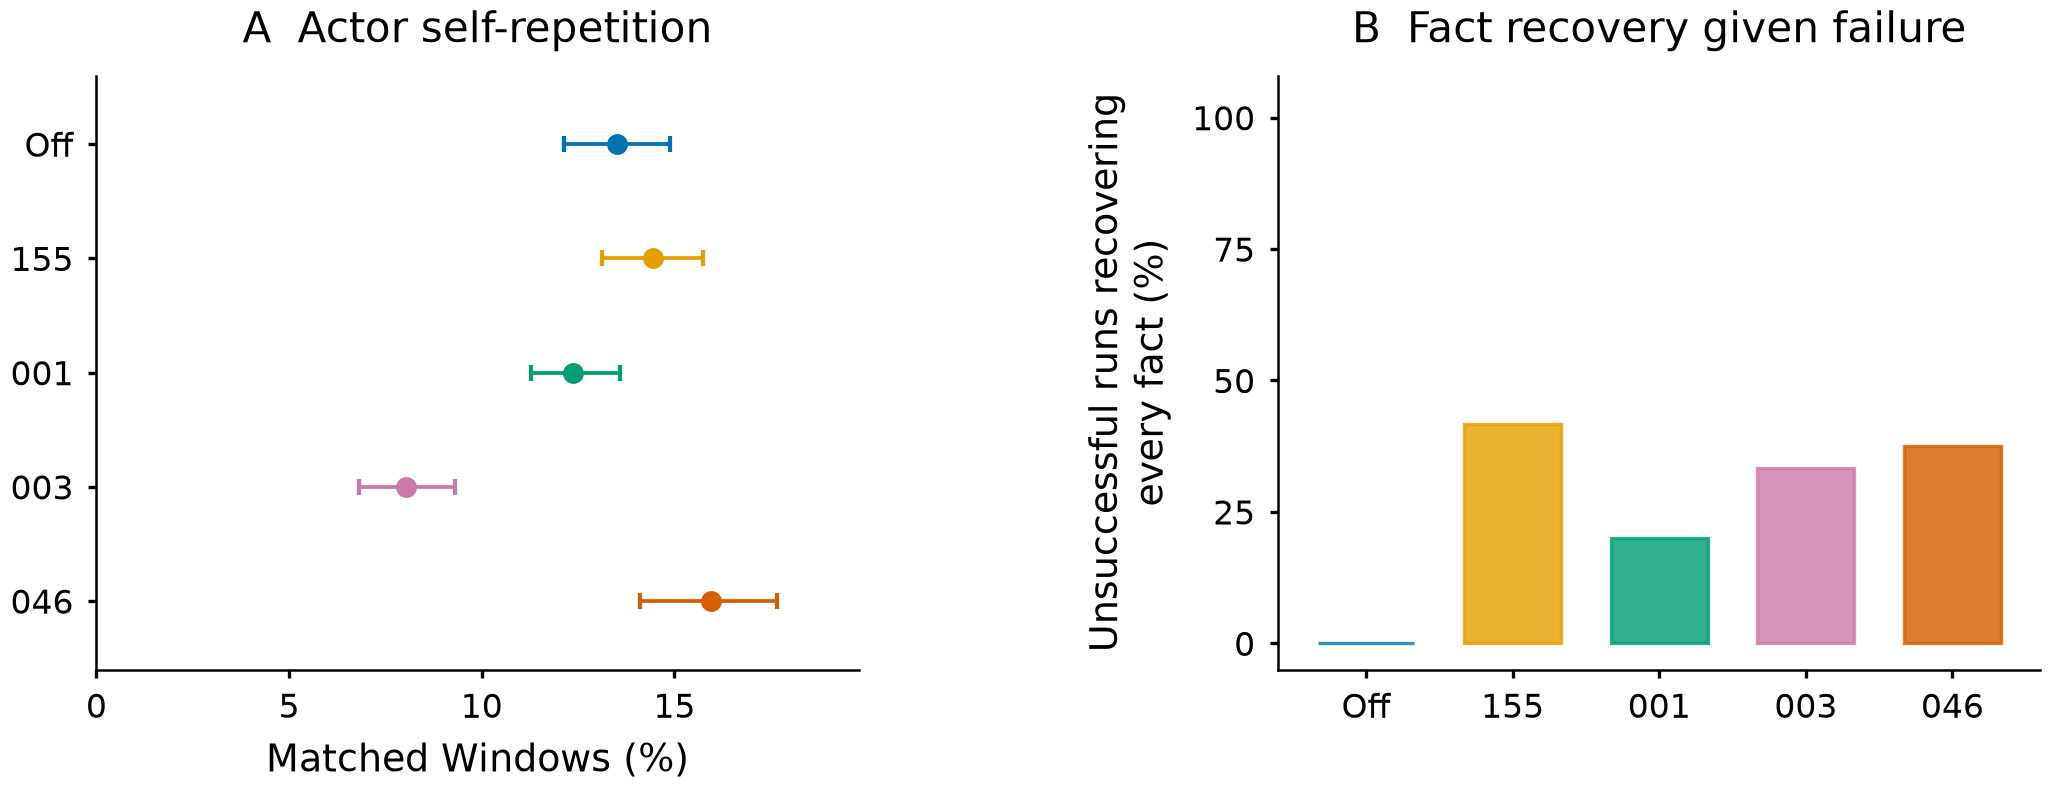

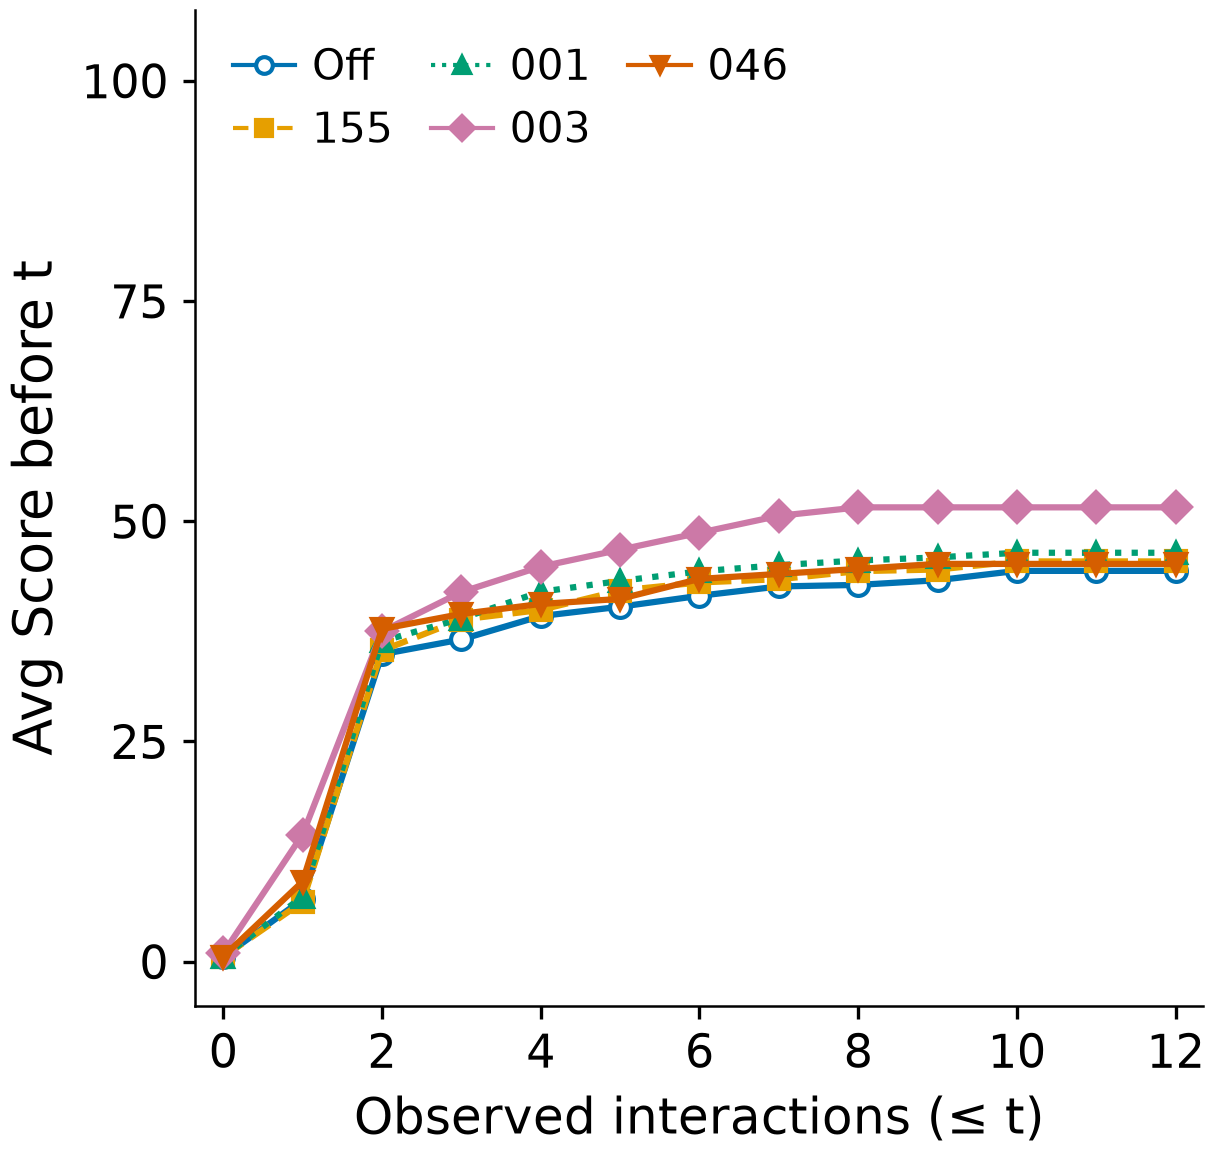

**A–B:** Existing actor self-repetition and failure-conditioned fact-recovery estimates, unchanged. **C:** The requested label “Avg Score before t” retains the original definition: sum final native scores for runs finishing at ≤ t, divided by all evaluable runs for that setting (fixed denominator). It is not M(t), the mean among completed runs.

In [1]:
# Existing main figure, split into A–B and C; estimators unchanged.
from pathlib import Path
import sys
from IPython.display import display, Image, Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'Experiment/shared/task_selection.csv').exists())
sys.path.insert(0,str(ROOT/'Experiment/09_offline_metric_suite/code'))
import plot_metric_suite_split as split
for fig in split.render():split.plot.plt.close(fig)
display(Image(filename=str(split.OUT/'metric_suite_AB.png'),width=1100))
display(Image(filename=str(split.OUT/'metric_suite_C.png'),width=750))
display(Markdown('**A–B:** Existing actor self-repetition and failure-conditioned fact-recovery estimates, unchanged. **C:** The requested label “Avg Score before t” retains the original definition: sum final native scores for runs finishing at ≤ t, divided by all evaluable runs for that setting (fixed denominator). It is not M(t), the mean among completed runs.'))
success_length_summary=split.success_length_summary
success_length_source_summary=split.success_length_source_summary
unsuccessful_recovery_summary=split.unsuccessful_recovery_summary


In [6]:
checks=subprocess.run([sys.executable,str(BASE/'code/test_metrics.py')],capture_output=True,text=True,check=True)
print(checks.stdout+checks.stderr)
print('Same-length SciConv matched pattern rates:',sorted({round(r['mean'],8) for r in s['repetition'] if r['variant']=='same_length' and r['level']=='source' and r['group']=='sciconvbench' and r['mean'] is not None}))
display(Markdown('**Notebook figure.** A: actor lexical self-repetition (≥3 corresponding word matches per six-word window), 79 common questions with ≥9-token message eligibility; source-balanced means and 95% study-cluster CIs. Window settings were selected from an exploratory grid. B: complete-fact recovery conditional on SciConv disambiguation failure (FRR = 0). Bars are equal-case means over failed trials; cases without failures are excluded separately for each setting. No CI is shown. C: cumulative native performance across all five benchmarks. At t, sum final native scores (0–100) of runs ending after ≤ t observed interactions and divide by all evaluable runs with complete traces for that persona. Partial credit is retained; this is not binary success probability. Later-finishing runs contribute only at their completion count; curves end at overall mean native performance. There are 1,958 included original runs; zero-scored missing submissions remain, infrastructure failures and incomplete traces are excluded. Trials count as runs. SciConv counts clarification exchanges; the other benchmarks count actor handoffs including required plan/result stages. These different protocols, distinct native metrics, variable source coverage and historical ASI evaluator differences limit cross-source interpretation. Curves do not establish within-run recovery or causal effects of extra turns. No CI is shown for C. Off/155/001 have three trials, 003/046 one.'))

NameError: name 'BASE' is not defined

## Exploratory actor word-window grid search
Windows: 4–9 words. Required matches: 3–9, restricted to threshold ≤ window size (27 combinations). A match requires at least k identical words **at corresponding positions** in one earlier actor-message window. No word reordering, stemming, synonyms or within-current-message self-comparisons.

All configurations use the same actor messages of at least nine words, the same eligible episodes, and questions available for all five settings. This differs from the current four-word figure eligibility and is reported separately. Rank by persona-off’s absolute source-balanced mean; also show whether off is actually the highest setting. The maximum is selected using observed data and is exploratory; pointwise intervals do not account for that selection. The main figure is not replaced by the selected configuration. No new model inference; this analysis writes only notebook outputs.

In [7]:
# Offline exploratory grid; only this notebook's output is saved.
from pathlib import Path
import sys, json, hashlib, itertools
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
import numpy as np
from numba import njit
from IPython.display import display, Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'Experiment/shared/task_selection.csv').exists())
sys.path.insert(0,str(ROOT/'Experiment/09_offline_metric_suite/code'))
from extract import DATA, ARMS, LABELS
from word_repetition import tokenize, SEGMENTER
from self_repetition import messages
from analyze import task_values, summary
from report import table
SEGMENTER.initialize()
GRID=[(n,k) for n in range(4,10) for k in range(3,10) if k<=n]

@njit(nogil=True)
def max_aligned_matches(current, offsets, indexed_rows, nrefs):
    counts=np.zeros(nrefs,np.int16)
    stamps=np.full(nrefs,-1,np.int64)
    best=np.zeros(current.shape[0],np.int16)
    n=current.shape[1]
    for i in range(current.shape[0]):
        for col in range(n):
            key=current[i,col]*n+col
            for at in range(offsets[key],offsets[key+1]):
                j=indexed_rows[at]
                if stamps[j]!=i:
                    stamps[j]=i;counts[j]=0
                counts[j]+=1
                if counts[j]>best[i]:best[i]=counts[j]
    return best

def best_matches(current, previous, n, vocab):
    ref=np.concatenate([np.lib.stride_tricks.sliding_window_view(x,n) for x in previous],axis=0)
    cur=np.lib.stride_tricks.sliding_window_view(current,n).copy()
    keys=(ref*n+np.arange(n)).ravel()
    order=np.argsort(keys,kind='stable')
    offsets=np.concatenate(([0],np.cumsum(np.bincount(keys,minlength=vocab*n))))
    return max_aligned_matches(cur,offsets,order//n,len(ref))

# Independent brute-force check, including repeated words, exact thresholds and alignment.
rng=np.random.default_rng(20261001)
for n in range(4,10):
    prev=[rng.integers(0,5,14),rng.integers(0,5,12)]
    cur=rng.integers(0,5,13)
    actual=best_matches(cur,prev,n,5)
    ref=np.concatenate([np.lib.stride_tricks.sliding_window_view(x,n) for x in prev])
    expected=np.array([np.max(np.sum(ref==w,axis=1)) for w in np.lib.stride_tricks.sliding_window_view(cur,n)])
    np.testing.assert_array_equal(actual,expected)
assert len(GRID)==27

snap=json.loads((DATA/'snapshot.json').read_text())
def episode_grid(trace):
    if trace.get('exclusion') is not None:return None
    raw=(ROOT/trace['trace_path']).read_bytes()
    assert hashlib.sha256(raw).hexdigest()==trace['sha256']
    events=[json.loads(line) for line in raw.splitlines() if line.strip()]
    text=messages(events,trace['source'],normalizer=tokenize)['actor']
    # Freeze the same eligible messages for all 27 definitions.
    text=[t for t in text if len(t)>=9]
    if len(text)<2:return None
    dictionary={w:i for i,w in enumerate(dict.fromkeys(w for t in text for w in t))}
    encoded=[np.array([dictionary[w] for w in t],dtype=np.int64) for t in text]
    values={pair:[] for pair in GRID}
    for t in range(1,len(encoded)):
        for n in range(4,10):
            best=best_matches(encoded[t],encoded[:t],n,len(dictionary))
            for k in range(3,n+1):values[(n,k)].append(100*float(np.mean(best>=k)))
    meta={k:trace[k] for k in ['source','task_id','study_id','family','arm','trial']}
    return meta|dict(eligible_messages=len(text),values={f'{n}:{k}':float(np.mean(v)) for (n,k),v in values.items()})
with ThreadPoolExecutor(max_workers=4) as pool:
    episodes=[r for r in pool.map(episode_grid,snap['traces']) if r is not None]
question_sets=[{(r['source'],r['task_id']) for r in episodes if r['arm']==a} for a in ARMS]
common=set.intersection(*question_sets)
episodes=[r for r in episodes if (r['source'],r['task_id']) in common]
assert common
results=[]
for n,k in GRID:
    record=dict(window=n,threshold=k,match_fraction=k/n)
    for arm in ARMS:
        rows=[r|dict(value=r['values'][f'{n}:{k}']) for r in episodes if r['arm']==arm]
        record[arm]=summary(task_values(rows,'value'),equal_source=True)
    baseline=record[ARMS[0]]['mean']
    other=[record[a]['mean'] for a in ARMS[1:]]
    record['off_minus_largest_persona']=baseline-max(other)
    record['off_rank']=1+sum(x>baseline+1e-12 for x in other)
    results.append(record)
# Every higher threshold is a subset of the lower-threshold matches, for fixed n.
for arm in ARMS:
    for n in range(4,10):
        vals=[r[arm]['mean'] for r in results if r['window']==n]
        assert all(a+1e-10>=b for a,b in zip(vals,vals[1:]))
ranked=sorted(results,key=lambda r:(-r[ARMS[0]]['mean'],r['window'],r['threshold']))
best_absolute=ranked[0]
best_relative=max(results,key=lambda r:r['off_minus_largest_persona'])
grid_search_result=dict(method='Actor only; exact equality at corresponding positions; >=k of n positions in any earlier same-role message window; no cross-message windows; Unicode word tokenizer as WORD_REPETITION.md. All messages have >=9 tokens for fixed eligibility across the grid. Average eligible later turns, saved trials within question, questions within source and five sources equally. Original episodes; common five-setting questions. CIs are pointwise and not adjusted for selecting the maximum.',questions=len(common),source_counts=dict(Counter(src for src,_ in common)),episodes_by_arm=dict(Counter(r['arm'] for r in episodes)),grid=results,best_absolute=best_absolute,best_relative=best_relative,input_sha256=hashlib.sha256((DATA/'snapshot.json').read_bytes()).hexdigest())
print('Fixed common panel:',len(common),'questions;',grid_search_result['source_counts'])
print('Eligible episodes:',grid_search_result['episodes_by_arm'])
display(Markdown(table(['Window','Minimum matching words','Off %','155 %','001 %','003 %','046 %','Off rank','Off − highest persona (pp)'],[[r['window'],r['threshold'],*[f"{r[a]['mean']:.3f}" for a in ARMS],r['off_rank'],f"{r['off_minus_largest_persona']:.3f}"] for r in ranked])))
print('Largest off mean:',best_absolute['window'],best_absolute['threshold'],best_absolute[ARMS[0]]['mean'])
print('Best off-minus-highest-persona:',best_relative['window'],best_relative['threshold'],best_relative['off_minus_largest_persona'])
print('Number of combinations where off is highest:',sum(r['off_rank']==1 for r in results))
display(Markdown(table(['Setting','Mean %','Pointwise 95% CI'],[[label,f"{best_absolute[a]['mean']:.3f}",f"[{best_absolute[a]['ci95'][0]:.3f}, {best_absolute[a]['ci95'][1]:.3f}]"] for a,label in zip(ARMS,LABELS)])))
# Machine-readable numeric output is embedded in the notebook, not a repository sidecar.
display({'application/json':grid_search_result},raw=True)


ModuleNotFoundError: No module named 'jieba'

## Grid-search summary

Fixed panel: 79 questions from all five benchmarks; actor messages only, at least nine words per included message. All 27 valid window/threshold combinations are listed above.

- Highest absolute off repetition: 3/9 matching positions, 21.971%; off ranks 3.
- Largest off score among combinations where off ranks first: 6/7, 0.825%.
- Largest lead over the highest-scoring persona: 8/9, 0.145 percentage points.

| Setting | 3 of 9 words (%) | 6 of 7 words (%) | 8 of 9 words (%) |
|---|---:|---:|---:|
| Off | 21.971 | 0.825 | 0.399 |
| 155 | 22.763 | 0.714 | 0.242 |
| 001 | 20.675 | 0.677 | 0.254 |
| 003 | 13.690 | 0.350 | 0.097 |
| 046 | 25.981 | 0.777 | 0.192 |

Off is highest at (window, minimum matches) = (7,6), (8,7), (9,7), (9,8). These configurations were selected from observed scores; ranking is descriptive, not a statistical-significance result. The existing main figure remains unchanged.

## Simulator at the selected setting
Offline counterpart of the actor grid: six-word windows, at least three corresponding matches, and the same minimum nine-token message eligibility. Match only earlier simulator messages in the same conversation; all five settings must have eligible data for an included question. This is a separately matched role panel.

In [ ]:
# Simulator counterpart of the selected actor grid setting: n=6, k=3.
# Same matching/tokenization and >=9-token message eligibility; no inference.
from pathlib import Path
import sys, json, hashlib, itertools
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
import numpy as np
from numba import njit
from IPython.display import display, Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'Experiment/shared/task_selection.csv').exists())
sys.path.insert(0,str(ROOT/'Experiment/09_offline_metric_suite/code'))
from extract import DATA, ARMS, LABELS
from word_repetition import tokenize, SEGMENTER
from self_repetition import messages
from analyze import task_values, summary
from report import table
SEGMENTER.initialize()
GRID=[(6,3)]

@njit(nogil=True)
def max_aligned_matches(current, offsets, indexed_rows, nrefs):
    counts=np.zeros(nrefs,np.int16)
    stamps=np.full(nrefs,-1,np.int64)
    best=np.zeros(current.shape[0],np.int16)
    n=current.shape[1]
    for i in range(current.shape[0]):
        for col in range(n):
            key=current[i,col]*n+col
            for at in range(offsets[key],offsets[key+1]):
                j=indexed_rows[at]
                if stamps[j]!=i:
                    stamps[j]=i;counts[j]=0
                counts[j]+=1
                if counts[j]>best[i]:best[i]=counts[j]
    return best

def best_matches(current, previous, n, vocab):
    ref=np.concatenate([np.lib.stride_tricks.sliding_window_view(x,n) for x in previous],axis=0)
    cur=np.lib.stride_tricks.sliding_window_view(current,n).copy()
    keys=(ref*n+np.arange(n)).ravel()
    order=np.argsort(keys,kind='stable')
    offsets=np.concatenate(([0],np.cumsum(np.bincount(keys,minlength=vocab*n))))
    return max_aligned_matches(cur,offsets,order//n,len(ref))

# Independent brute-force check, including repeated words, exact thresholds and alignment.
rng=np.random.default_rng(20261001)
for n in [6]:
    prev=[rng.integers(0,5,14),rng.integers(0,5,12)]
    cur=rng.integers(0,5,13)
    actual=best_matches(cur,prev,n,5)
    ref=np.concatenate([np.lib.stride_tricks.sliding_window_view(x,n) for x in prev])
    expected=np.array([np.max(np.sum(ref==w,axis=1)) for w in np.lib.stride_tricks.sliding_window_view(cur,n)])
    np.testing.assert_array_equal(actual,expected)
assert GRID==[(6,3)]

snap=json.loads((DATA/'snapshot.json').read_text())
def episode_grid(trace):
    if trace.get('exclusion') is not None:return None
    raw=(ROOT/trace['trace_path']).read_bytes()
    assert hashlib.sha256(raw).hexdigest()==trace['sha256']
    events=[json.loads(line) for line in raw.splitlines() if line.strip()]
    text=messages(events,trace['source'],normalizer=tokenize)['simulator']
    # Freeze the same eligible messages for all 27 definitions.
    text=[t for t in text if len(t)>=9]
    if len(text)<2:return None
    dictionary={w:i for i,w in enumerate(dict.fromkeys(w for t in text for w in t))}
    encoded=[np.array([dictionary[w] for w in t],dtype=np.int64) for t in text]
    values={pair:[] for pair in GRID}
    for t in range(1,len(encoded)):
        for n in [6]:
            best=best_matches(encoded[t],encoded[:t],n,len(dictionary))
            for k in [3]:values[(n,k)].append(100*float(np.mean(best>=k)))
    meta={k:trace[k] for k in ['source','task_id','study_id','family','arm','trial']}
    return meta|dict(eligible_messages=len(text),values={f'{n}:{k}':float(np.mean(v)) for (n,k),v in values.items()})
with ThreadPoolExecutor(max_workers=4) as pool:
    episodes=[r for r in pool.map(episode_grid,snap['traces']) if r is not None]
question_sets=[{(r['source'],r['task_id']) for r in episodes if r['arm']==a} for a in ARMS]
common=set.intersection(*question_sets)
episodes=[r for r in episodes if (r['source'],r['task_id']) in common]
assert common

simulator_6_3_result=dict(window=6,threshold=3,role='simulator',questions=len(common),source_counts=dict(Counter(src for src,_ in common)),episodes_by_arm=dict(Counter(r['arm'] for r in episodes)),minimum_message_tokens=9)
for arm in ARMS:
    rows=[r|dict(value=r['values']['6:3']) for r in episodes if r['arm']==arm]
    simulator_6_3_result[arm]=summary(task_values(rows,'value'),equal_source=True)
print('Simulator fixed common panel:',len(common),simulator_6_3_result['source_counts'])
display(Markdown(table(['Setting','Mean %','95% CI'],[[label,f"{simulator_6_3_result[a]['mean']:.3f}",str(simulator_6_3_result[a]['ci95'])] for a,label in zip(ARMS,LABELS)])))
display({'application/json':{'simulator_6_3_result':simulator_6_3_result}},raw=True)


## Matched successful SciConv interactions

Both panels use the same 29 shared-success SciConv questions. Left: 0/1/2/3+ distributions with pointwise 95% whole-question bootstrap CIs (20,000 paired resamples). Right: successful-run paired means. Other benchmarks do not contribute.

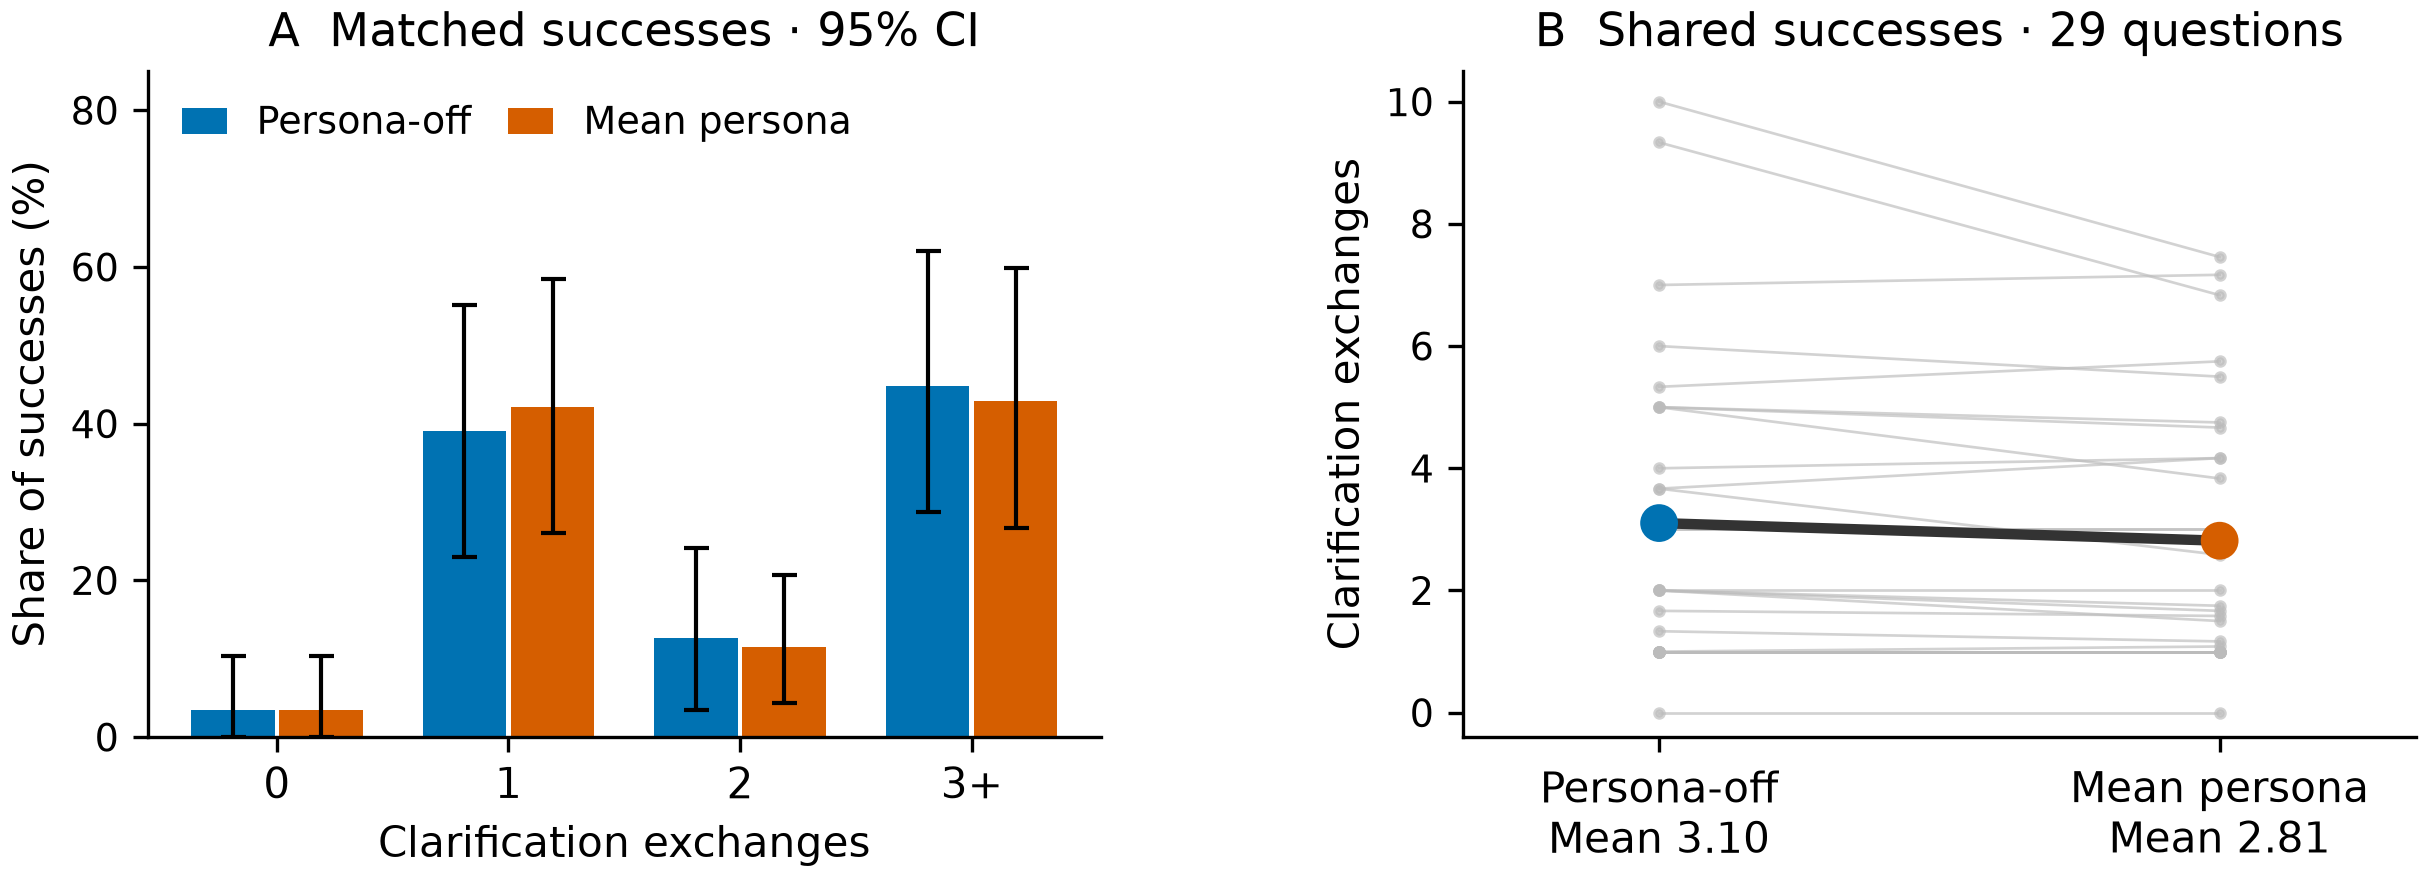

**Clarification lengths on shared successful SciConv questions.** Both panels include the 29 questions with at least one native-score-100 episode under every setting (off/155/001/003/046). Only successful repeats contribute; zero-exchange successes are retained. **A**, Distribution over 0, 1, 2 and 3+ clarification exchanges. Compute bin proportions across successful repeats within each question/setting, give questions equal weights, and give the four personas equal weights for mean persona. Each series sums to 100%; these are shares of successful runs, not success rates. Error bars are pointwise 95% percentile confidence intervals from 20,000 bootstrap resamples of the 29 whole questions with replacement (seed 20261005). Each sampled question carries all five settings and all observed repeats together, preserving their dependence; repeats and personas are not independently resampled. Intervals condition on the observed matched-success subset and do not capture selection uncertainty or constitute a paired significance test. **B**, Thin gray lines connect each question's successful-repeat mean for off to its equally weighted mean across four personas; the thick line connects equal-question means (3.10 versus 2.81 exchanges). Panel B has no confidence intervals. Unequal repeat counts remain. These success-conditioned estimates do not establish that persona injection improves overall efficiency or that more turns cause success. Overall success across all 40 SciConv questions was 85.0% off versus 83.75% mean persona.

## Reproduction
Run `code/plot_successful_interactions.py` or the final notebook section. Input: `data/snapshot.json`; figure source tables: `data/successful_interactions/matched_distribution*.csv` and SciConv rows of `all_benchmark_pairs.csv`. Other benchmark coverage audits remain supporting data but do not contribute to the figure. PDF/SVG/PNG and QA: `figures/successful_interactions/`.


In [1]:
from pathlib import Path
import sys
from IPython.display import display, Image, Markdown
import matplotlib.pyplot as plt
_here = Path.cwd()
_root = next(p for p in [_here, *_here.parents] if (p / "Experiment/09_offline_metric_suite/code/plot_successful_interactions.py").exists())
_base = _root / "Experiment/09_offline_metric_suite"
sys.path.insert(0, str(_base / "code"))
import plot_successful_interactions
plt.close(plot_successful_interactions.render())
display(Image(filename=str(_base / "figures/successful_interactions/successful_interactions.png"), width=1100))
display(Markdown((_base / "SUCCESSFUL_INTERACTIONS.md").read_text().split("## Candidate caption\n", 1)[1]))


## M(t) preview — mean performance among completed runs

Same all-benchmark data and weighting as original Panel C; denominator now includes only episodes ending by t. Source composition and count tables accompany the preview. Prior figures are unchanged.

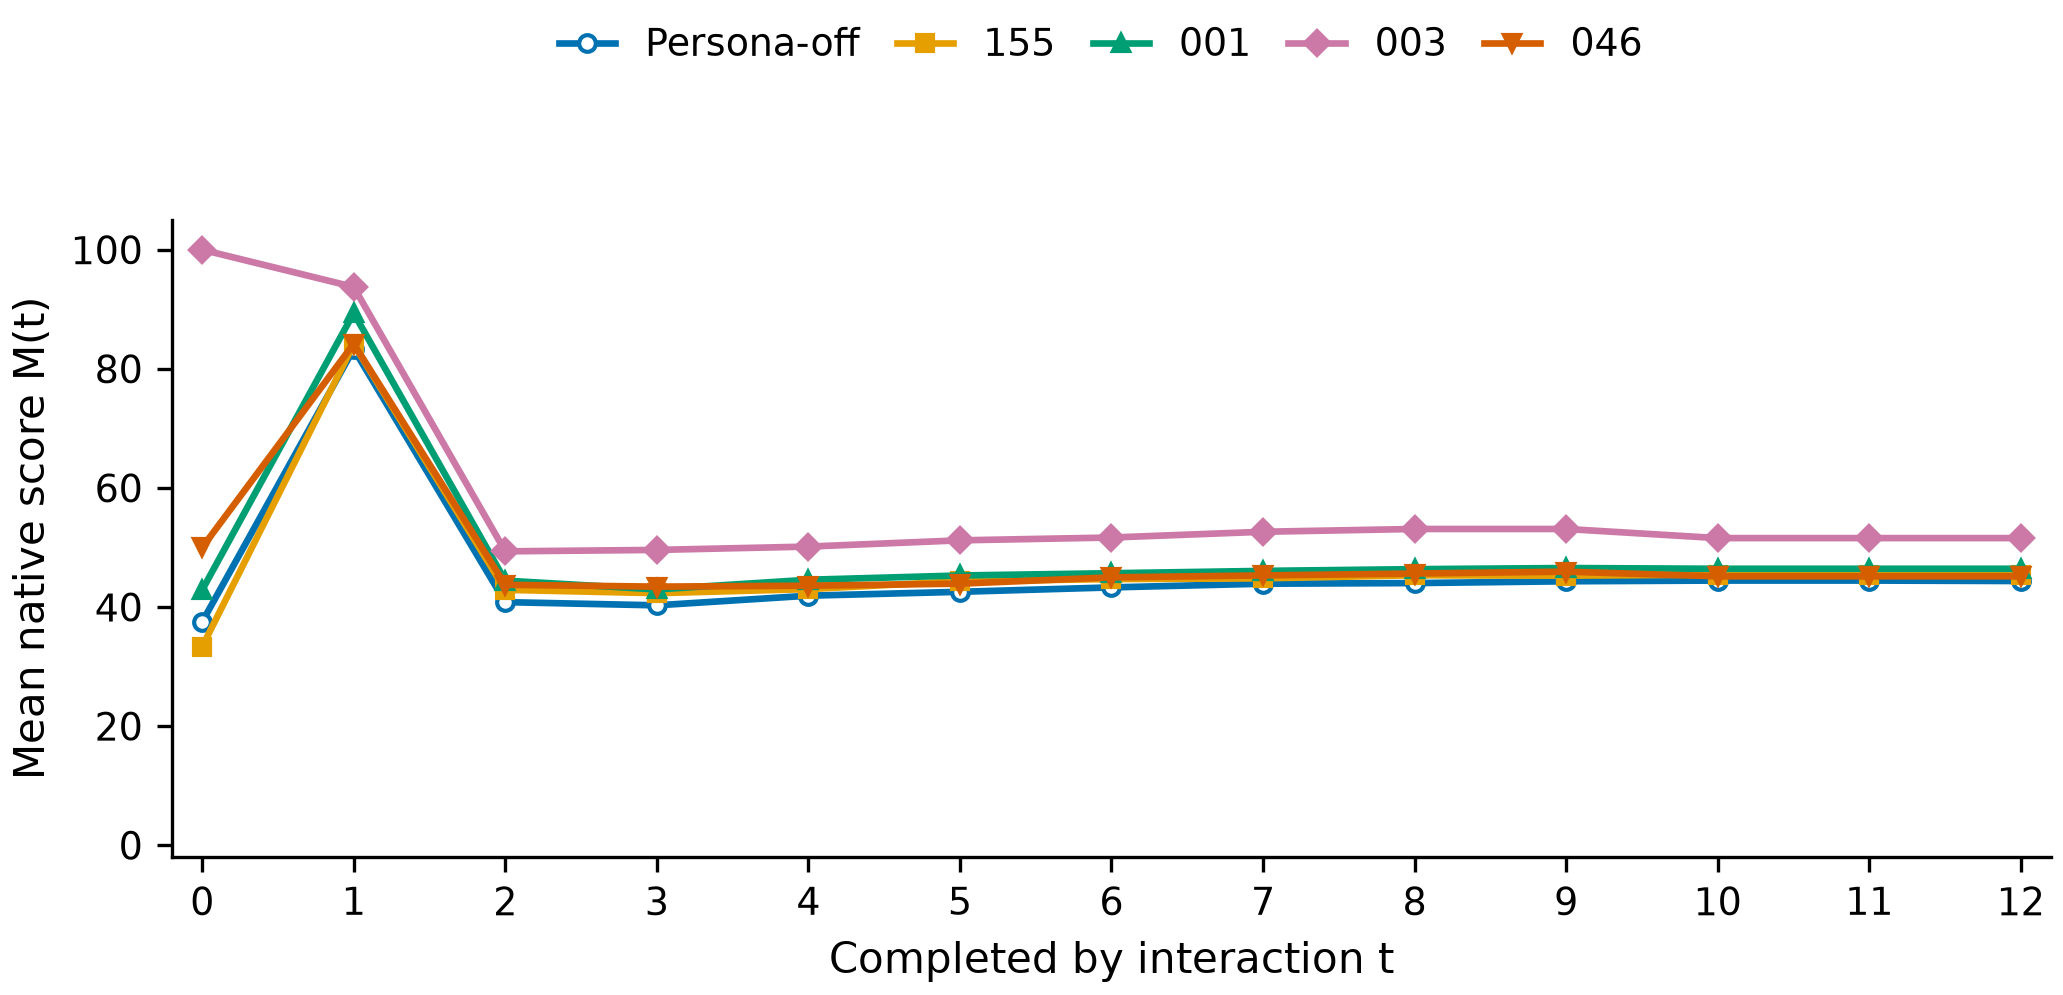

# Mean performance among runs completed by t

## Figure contract
Change only the denominator of the existing all-benchmark Panel C estimator for comparison: use completed-by-t episodes rather than all episodes. Retain its five settings, 1,958 evaluable traces, episode weighting, native final scores, and protocol interaction counts. Keep the existing figure unchanged; add a preview. No new inference or uncertainty claim.

## Candidate caption
**Mean final performance among runs completed by each interaction threshold.** For each setting, M(t) is the sum of final native scores for episodes whose observed interaction count is at most t, divided by the number of those episodes. The same 1,958 evaluable original Astra episodes as the existing Panel C are used across all five benchmarks, with off/155/001/003/046 shown separately. Scores are on 0–100 and retain partial credit; this is not uniformly a binary success rate. Both numerator and denominator change as episodes finish, so curves can rise or fall. Episodes, not benchmarks, receive equal weights, matching the original Panel C; the preview changes only its denominator. Benchmark and question composition therefore change with t. Zero-denominator points are undefined rather than assigned zero. SciConv counts clarification exchanges, whereas the other sources count actor handoffs including required plan/result stages. M(t) uses final scores from different observed episodes and is not performance after t interactions for a fixed cohort or an experimentally assigned interaction budget. A rise does not establish within-run recovery or a causal benefit of extra interaction. No CIs are displayed in this descriptive line preview. Per-setting denominators and per-source composition are provided in the source tables.

## Reproduction
Run `code/plot_completed_mean.py` or execute the M(t) preview section of `metric_suite.ipynb`. Source tables and hashes: `data/completed_mean/`; editable PDF/SVG and PNG: `figures/completed_mean/`. Earlier figures are unchanged.


**Mean score (number of completed episodes)**

| t | Persona-off | 155 | 001 | 003 | 046 |
|---|---:|---:|---:|---:|---:|
| 0 | 37.50 (n=8) | 33.33 (n=9) | 42.86 (n=7) | 100.00 (n=1) | 50.00 (n=2) |
| 1 | 83.33 (n=48) | 84.09 (n=44) | 89.36 (n=47) | 93.75 (n=16) | 84.21 (n=19) |
| 2 | 40.82 (n=483) | 42.89 (n=449) | 44.43 (n=465) | 49.35 (n=79) | 43.73 (n=152) |
| 3 | 40.29 (n=513) | 42.33 (n=500) | 42.96 (n=515) | 49.59 (n=88) | 43.42 (n=160) |
| 4 | 41.90 (n=529) | 43.01 (n=506) | 44.58 (n=535) | 50.15 (n=93) | 43.58 (n=164) |
| 5 | 42.55 (n=535) | 44.33 (n=518) | 45.30 (n=542) | 51.20 (n=95) | 43.92 (n=165) |
| 6 | 43.30 (n=542) | 44.69 (n=525) | 45.68 (n=551) | 51.67 (n=98) | 44.99 (n=170) |
| 7 | 43.92 (n=548) | 44.82 (n=528) | 46.07 (n=555) | 52.64 (n=100) | 45.31 (n=171) |
| 8 | 44.02 (n=549) | 45.34 (n=533) | 46.36 (n=558) | 53.11 (n=101) | 45.63 (n=172) |
| 9 | 44.32 (n=552) | 45.27 (n=536) | 46.55 (n=560) | 53.11 (n=101) | 45.94 (n=173) |
| 10 | 44.44 (n=564) | 45.44 (n=545) | 46.42 (n=568) | 51.58 (n=104) | 45.16 (n=176) |
| 11 | 44.44 (n=564) | 45.44 (n=545) | 46.42 (n=568) | 51.58 (n=104) | 45.16 (n=176) |
| 12 | 44.37 (n=565) | 45.44 (n=545) | 46.42 (n=568) | 51.58 (n=104) | 45.16 (n=176) |


In [1]:
from pathlib import Path
import sys,csv
from IPython.display import display,Image,Markdown
import matplotlib.pyplot as plt
_here=Path.cwd()
_root=next(p for p in [_here,*_here.parents] if (p/'Experiment/09_offline_metric_suite/code/plot_completed_mean.py').exists())
_base=_root/'Experiment/09_offline_metric_suite'
sys.path.insert(0,str(_base/'code'))
import plot_completed_mean
plt.close(plot_completed_mean.render())
display(Image(filename=str(_base/'figures/completed_mean/completed_mean.png'),width=1100))
display(Markdown((_base/'MT_PREVIEW.md').read_text()))
_rows=list(csv.DictReader((_base/'data/completed_mean/estimates.csv').open()))
_table='| t | '+' | '.join(plot_completed_mean.LABELS)+' |\n|---|'+'---:|'*5+'\n'
for t in sorted({int(r['t']) for r in _rows}):
    _table+='| '+str(t)+' | '+' | '.join(f"{float(r['mean']):.2f} (n={r['finished_runs']})" if r['mean'] else 'NA' for arm in plot_completed_mean.ARMS for r in _rows if r['arm']==arm and int(r['t'])==t)+' |\n'
display(Markdown('**Mean score (number of completed episodes)**\n\n'+_table))
